##0. Описание задачи
Датасет Steam Games Dataset (Kaggle) содержит информацию о +-126 тысячах игр, опубликованных в интернет-магазине Steam. Каждая строка - одна игра. Для каждой игры указаны: дата выхода, цена (в долларах), возрастной рейтинг, количество DLC(дополнений к игре) и достижений, поддерживаемые платформы (Windows, Mac, Linux), количество положительных и отрицательных отзывов, примерное число покупок, жанры, а также текстовые поля (описание, ссылки, скриншоты), которые мы использовать не будем.

Требуется предсказать цену игры Price по её остальным характеристикам. Цена — количественный признак, поэтому это задача регрессии.


In [ ]:
import numpy as np              # Массивы (матрицы, векторы, линейная алгебра)
import matplotlib.pyplot as plt # Научная графика
%matplotlib inline
    # Говорим jupyter'у, чтобы весь графический вывод был в браузере, а не в отдельном окне
import pandas as pd             # Таблицы и временные ряды (dataframe, series)
import seaborn as sns           # Еще больше красивой графики для визуализации данных
import sklearn                  # Алгоритмы машинного обучения
import kagglehub
import os
pd.set_option('display.max_columns', None)

In [ ]:
path = kagglehub.dataset_download("fronkongames/steam-games-dataset")

100%|██████████| 305M/305M [00:03<00:00, 92.9MB/s]

Extracting files...


#1. Читаем данные

В заголовке файла 'games.csv' есть ошибка: названия столбцов 'Discount' и 'DLC count'
склеены в одно — 'DiscountDLC count'. Из-за этого названий на одно меньше, чем значений
в строках, и при чтении все столбцы сдвигаются. Исправим это.

In [ ]:
data_raw = pd.read_csv(os.path.join(path, "games.csv"))

cols = list(data_raw.columns)
i = cols.index('DiscountDLC count')
correct_cols = cols[:i] + ['Discount', 'DLC count'] + cols[i+1:]

data_raw = data_raw.reset_index()
data_raw.columns = correct_cols

print(data_raw.shape)
data_raw.head()

(125855, 40)


,AppID,Name,Release date,Estimated owners,Peak CCU,Required age,Price,Discount,DLC count,About the game,Supported languages,Full audio languages,Reviews,Header image,Website,Support url,Support email,Windows,Mac,Linux,Metacritic score,Metacritic url,User score,Positive,Negative,Score rank,Achievements,Recommendations,Notes,Average playtime forever,Average playtime two weeks,Median playtime forever,Median playtime two weeks,Developers,Publishers,Categories,Genres,Tags,Screenshots,Movies
0,2539430,Black Dragon Mage Playtest,"Aug 1, 2023",0 - 0,0,0,0.00,0,0,NaN,[],[],NaN,https://shared.akamai.steamstatic.com/store_it...,NaN,NaN,NaN,True,False,False,0,NaN,0,0,0,NaN,0,0,NaN,0,0,0,0,NaN,NaN,NaN,NaN,NaN,https://shared.akamai.steamstatic.com/store_it...,NaN
1,496350,Supipara - Chapter 1 Spring Has Come!,"Jul 29, 2016",0 - 20000,0,0,5.24,65,0,"Springtime, April: when the cherry trees come ...",['English'],[],NaN,https://shared.akamai.steamstatic.com/store_it...,http://mangagamer.org/supipara,http://mangagamer.com,support@mangagamer.com,True,False,False,0,NaN,0,252,3,NaN,0,231,NaN,8,0,8,0,minori,MangaGamer,"Single-player,Steam Trading Cards,Steam Cloud,...",Adventure,"Adventure,Visual Novel,Anime,Cute",https://shared.akamai.steamstatic.com/store_it...,NaN
2,1034400,Mystery Solitaire The Black Raven,"May 6, 2019",0 - 20000,0,0,4.99,0,0,"Immerse yourself in the most beloved, mystical...","['English', 'French', 'German', 'Russian']",[],NaN,https://shared.akamai.steamstatic.com/store_it...,https://www.facebook.com/8FloorGames/,https://www.facebook.com/8FloorGames,support@8floor.net,True,True,False,0,NaN,0,21,3,NaN,0,0,NaN,0,0,0,0,Somer Games,8floor,"Single-player,Family Sharing",Casual,"Casual,Card Game,Solitaire,Puzzle,Hidden Objec...",https://shared.akamai.steamstatic.com/store_it...,NaN
3,3292190,버튜버 파라노이아 - Vtuber Paranoia,"Oct 31, 2024",0 - 20000,1,0,8.99,0,1,"synopsis 'Hello, I'm Hiyoro, a new YouTuber!' ...",['Korean'],['Korean'],NaN,https://shared.akamai.steamstatic.com/store_it...,NaN,NaN,yujingamesc@gmail.com,True,False,False,0,NaN,0,0,0,NaN,19,0,The game includes the following elements. 1. G...,0,0,0,0,유진게임즈,유진게임즈,"Single-player,Steam Achievements,Family Sharing","Casual,Indie,Simulation",NaN,https://shared.akamai.steamstatic.com/store_it...,NaN
4,3631080,Maze Quest VR,"Apr 24, 2025",0 - 20000,0,0,4.99,0,0,Its not just a Maze; its a Quest! Enter the ca...,['English'],['English'],NaN,https://shared.akamai.steamstatic.com/store_it...,https://www.realityexpanded.com/books-games,https://www.realityexpanded.com,support@realityexpanded.com,True,False,False,0,NaN,0,0,0,NaN,0,0,NaN,0,0,0,0,Reality Expanded LLC,Reality Expanded LLC,"Single-player,VR Only,Steam Leaderboards,Famil...","Action,Early Access",NaN,https://shared.akamai.steamstatic.com/store_it...,NaN


Каждая строка таблицы — одна игра. Всего 125 855 игр и 40 столбцов.

**Оставляем для работы:**
- `Price` - цена в долларах (**целевая переменная**, её предсказываем)
- `Release date` - дата выхода (достанем из неё год)
- `Estimated owners` - примерное число владельцев, записано диапазоном ("0 - 20000"), будем испольщовать среднее
- `Peak CCU` - максимальное число одновременных игроков
- `Required age` - возрастное ограничение
- `DLC count` - количество дополнений
- `Windows`, `Mac`, `Linux` - поддерживаемые платформы (бинарные признаки)
- `Metacritic score` - оценки критиков и пользователей
- `Positive`, `Negative` - число положительных и отрицательных отзывов
- `Achievements` - количество достижений
- `Recommendations` - число рекомендаций
- `Average playtime forever`, `Median playtime forever` - среднее и медианное время в игре (в минутах)
- `Genres` - жанры (у игры может быть несколько)

**Выбрасываем:**
- `AppID`, `Name` - уникальны для каждой игры, ничего не говорят о цене
- `About the game`, `Reviews`, `Notes`, `Supported languages`, `Full audio languages` - длинный текст, который не можем использовать
- `Header image`, `Website`, `Support url`, `Support email`, `Metacritic url`, `Screenshots`, `Movies` - ссылки и контакты
- `Developers`, `Publishers` - десятки тысяч разных значений, закодировать их разумно не получится
- `Categories`, `Tags` - похожи на жанры; для простоты ограничимся жанрами
- `Discount` - временная скидка в момент сбора данных, а не свойство игры
- `Score rank` - почти полностью пустой
- `Average/Median playtime two weeks` - время игры только за последние две недели, для большинства игр равно 0
- `user score` - у 99.5% игр равен 0, признак практически константный
**Типы оставленных признаков:**
- числовые - `Price`, `Peak CCU`, `Required age`, `DLC count`,
оценки, отзывы, достижения, время игры;
- бинарные - `Windows`, `Mac`, `Linux`;
- категориальные - `Genres`;
- текстовые, которые нужно превратить в числа, - `Release date`, `Estimated owners`.

In [ ]:
keep = ['Price',
        'Release date', 'Estimated owners', 'Peak CCU', 'Required age',
        'DLC count', 'Windows', 'Mac', 'Linux',
        'Metacritic score', 'Positive', 'Negative',
        'Achievements', 'Recommendations',
        'Average playtime forever', 'Median playtime forever',
        'Genres']

data = data_raw[keep].copy()

data['Year'] = pd.to_datetime(data['Release date'], errors='coerce').dt.year

owners = data['Estimated owners'].str.split(' - ', expand=True).astype(float)
data['Owners'] = (owners[0] + owners[1]) / 2

data = data.drop(['Release date', 'Estimated owners'], axis=1)

print(data.shape)
data.head()

(125855, 17)


,Price,Peak CCU,Required age,DLC count,Windows,Mac,Linux,Metacritic score,Positive,Negative,Achievements,Recommendations,Average playtime forever,Median playtime forever,Genres,Year,Owners
0,0.00,0,0,0,True,False,False,0,0,0,0,0,0,0,NaN,2023,0.0
1,5.24,0,0,0,True,False,False,0,252,3,0,231,8,8,Adventure,2016,10000.0
2,4.99,0,0,0,True,True,False,0,21,3,0,0,0,0,Casual,2019,10000.0
3,8.99,1,0,1,True,False,False,0,0,0,19,0,0,0,"Casual,Indie,Simulation",2024,10000.0
4,4.99,0,0,0,True,False,False,0,0,0,0,0,0,0,"Action,Early Access",2025,10000.0


#2 - 3. Визуализируем данные и вычисляем основные характеристики (среднее, разброс, корреляционную матрицу и т.д.), а так же работаем с выбросами. Интерпретируем.

In [ ]:
data.describe()

,Price,Peak CCU,Required age,DLC count,Metacritic score,Positive,Negative,Achievements,Recommendations,Average playtime forever,Median playtime forever,Year,Owners
count,125855.000000,1.258550e+05,125855.000000,125855.000000,125855.000000,1.258550e+05,1.258550e+05,125855.000000,1.258550e+05,1.258550e+05,1.258550e+05,125855.000000,1.258550e+05
mean,4.811174,5.318720e+01,0.165365,0.535434,2.500083,1.018182e+03,1.648786e+02,17.922220,9.380399e+02,2.027568e+02,1.691803e+02,2021.647300,8.354869e+04
std,12.489329,3.681083e+03,1.642666,14.328417,13.492922,2.772782e+04,5.305001e+03,139.696425,2.159585e+04,1.107222e+04,1.105725e+04,3.309018,1.273025e+06
min,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,1997.000000,0.000000e+00
25%,0.590000,0.000000e+00,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,2020.000000,1.000000e+04
50%,2.390000,0.000000e+00,0.000000,0.000000,0.000000,4.000000e+00,1.000000e+00,2.000000,0.000000e+00,0.000000e+00,0.000000e+00,2022.000000,1.000000e+04
75%,5.545000,0.000000e+00,0.000000,0.000000,0.000000,3.500000e+01,1.000000e+01,19.000000,0.000000e+00,0.000000e+00,0.000000e+00,2024.000000,1.000000e+04
max,999.980000,1.013936e+06,21.000000,3703.000000,97.000000,7.642084e+06,1.173003e+06,9821.000000,4.830455e+06,3.429544e+06,3.429544e+06,2026.000000,1.500000e+08


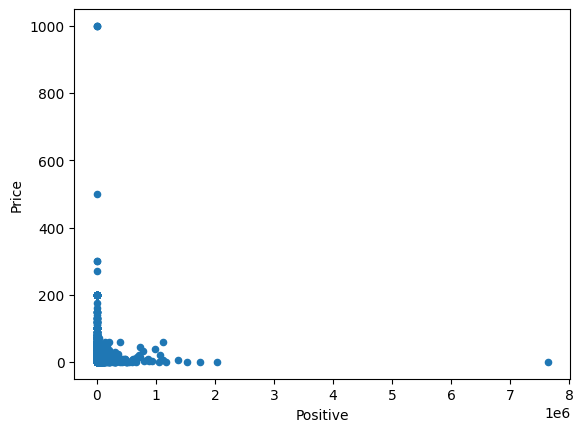

In [ ]:
data.plot(kind='scatter', x='Positive', y='Price')
pass

In [ ]:
data['Price'].quantile([0.005,.01,.05,.1,.5,.9,.95,.99,.995])

,Price
0.005,0.00
0.010,0.00
0.050,0.00
0.100,0.00
0.500,2.39
0.900,9.99
0.950,14.99
0.990,29.99
0.995,49.99


In [ ]:
data['Positive'].quantile([0.005,.01,.05,.1,.5,.9,.95,.99,.995])

,Positive
0.005,0.00
0.010,0.00
0.050,0.00
0.100,0.00
0.500,4.00
0.900,276.00
0.950,1031.30
0.990,12869.52
0.995,29450.99


Основная масса точек на диаграмме рассеяния находится в левом нижнем углу. Отдельные игры
сильно выпадают из общей картины: цена до 1000 доллоров 49.99, число положительных отзывов до 7.6 млн.
Это выбросы. По квантилям видно, что 99% цен лежат в диапазоне от 0 до 1289 долларов,
а 99% значений Positive — от 0 до 29450


In [ ]:
rows_to_drop = data[
    (data['Price'] < data['Price'].quantile(0.005)) | (data['Price'] > data['Price'].quantile(0.995)) |
    (data['Positive'] < data['Positive'].quantile(0.005)) | (data['Positive'] > data['Positive'].quantile(0.995))].index
data = data.drop(rows_to_drop)
data.shape

(124605, 17)

In [ ]:
data.describe()

,Price,Peak CCU,Required age,DLC count,Metacritic score,Positive,Negative,Achievements,Recommendations,Average playtime forever,Median playtime forever,Year,Owners
count,124605.000000,124605.000000,124605.000000,124605.000000,124605.000000,124605.000000,124605.000000,124605.000000,124605.000000,1.246050e+05,1.246050e+05,124605.000000,1.246050e+05
mean,4.135551,10.696970,0.141864,0.493351,2.280262,288.927619,59.846483,17.732699,305.478793,1.880641e+02,1.655319e+02,2021.661410,4.474114e+04
std,5.395949,575.854662,1.520222,14.294351,12.832005,1654.445380,474.895969,140.177902,2593.330226,1.112085e+04,1.111172e+04,3.293378,2.612003e+05
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,1997.000000,0.000000e+00
25%,0.550000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,2020.000000,1.000000e+04
50%,2.240000,0.000000,0.000000,0.000000,0.000000,4.000000,1.000000,2.000000,0.000000,0.000000e+00,0.000000e+00,2023.000000,1.000000e+04
75%,5.190000,0.000000,0.000000,0.000000,0.000000,34.000000,9.000000,18.000000,0.000000,0.000000e+00,0.000000e+00,2024.000000,1.000000e+04
max,49.990000,164168.000000,21.000000,3703.000000,96.000000,29332.000000,87986.000000,9821.000000,342882.000000,3.429544e+06,3.429544e+06,2026.000000,3.500000e+07


Помимо Price и Positive, сильные выбросы есть и в других признаках (это видно по describe()
и по стандартизированным данным: некоторые значения отстоят от среднего на сотни стандартных
отклонений). Метод ближайших соседей чувствителен к таким значениям, так как он работает
с расстояниями. Удалим строки, в которых какой-либо из этих признаков превышает квантиль 0.995.
Нижнюю границу не используем: минимальное значение этих признаков 0

In [ ]:
cols = ['Peak CCU', 'DLC count', 'Negative', 'Recommendations',
        'Achievements', 'Average playtime forever', 'Median playtime forever', 'Owners']

data[cols].quantile([0.5, 0.9, 0.95, 0.99, 0.995])

,Peak CCU,DLC count,Negative,Recommendations,Achievements,Average playtime forever,Median playtime forever,Owners
0.500,0.00,0.0,1.00,0.00,2.0,0.00,0.0,10000.0
0.900,2.00,1.0,63.00,267.00,38.0,216.00,205.0,75000.0
0.950,7.00,1.0,186.00,887.00,54.0,438.00,375.0,150000.0
0.990,113.00,6.0,1226.96,7215.88,100.0,1882.96,1465.0,750000.0
0.995,264.98,10.0,2219.98,12879.60,129.0,3349.96,2534.0,1500000.0


In [ ]:
upper = data[cols].quantile(0.995)

rows_to_drop = data[(data[cols] > upper).any(axis=1)].index
data = data.drop(rows_to_drop)
data.shape

(121671, 17)

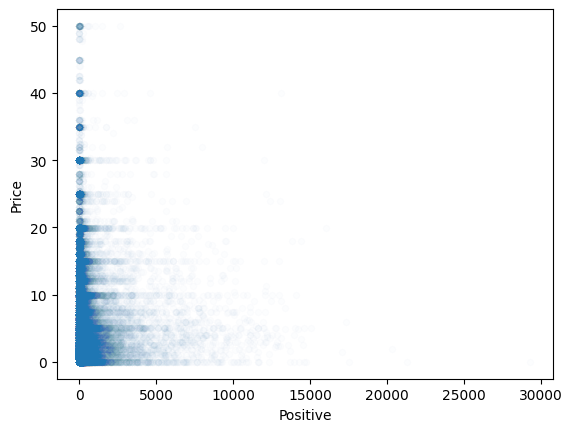

In [ ]:
data.plot(kind='scatter', x='Positive', y='Price', alpha=.01)
pass

Цены сосредоточены на нескольких «типичных» значениях (горизонтальные полосы около $10, $15,
$20, $30, $40, $50). У большинства игр мало положительных отзывов. Явной зависимости цены от
числа отзывов не видно: игры с большим числом отзывов встречаются во всех ценовых
категориях, в том числе бесплатные. В отличие от задачи о квартирах, где цена сильно зависела
от площади, здесь нет одного признака, который хорошо определяет цену.

In [ ]:
data['Mac'].value_counts()

,count
Mac,
False,101173
True,20498


Цвет точек — поддержка Mac, размер — число достижений


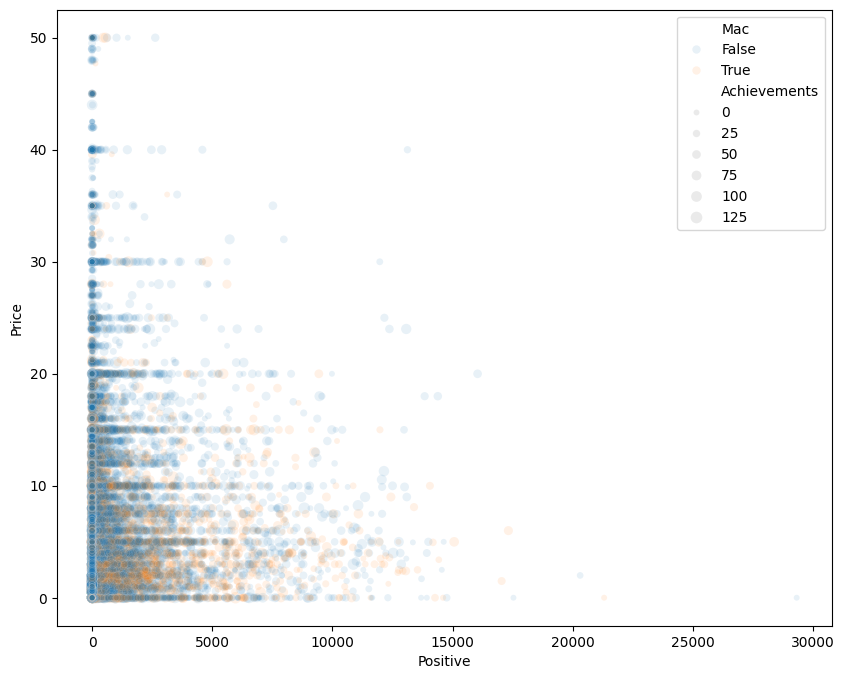

In [ ]:
plt.figure(figsize=(10, 8))
sns.scatterplot(x='Positive', y='Price', size='Achievements', hue='Mac', data=data, alpha=0.1)
pass

Игры с поддержкой macOS чаще встречаются среди игр с большим числом положительных отзывов,
то есть среди более популярных игр. По цене заметного различия между группами не видно.
Размер точек (число достижений) почти не различается: в признаке Achievements есть игры с
несколькими тысячами достижений, из-за чего различия между обычными играми незаметны.

Попарные диаграммы рассеяния


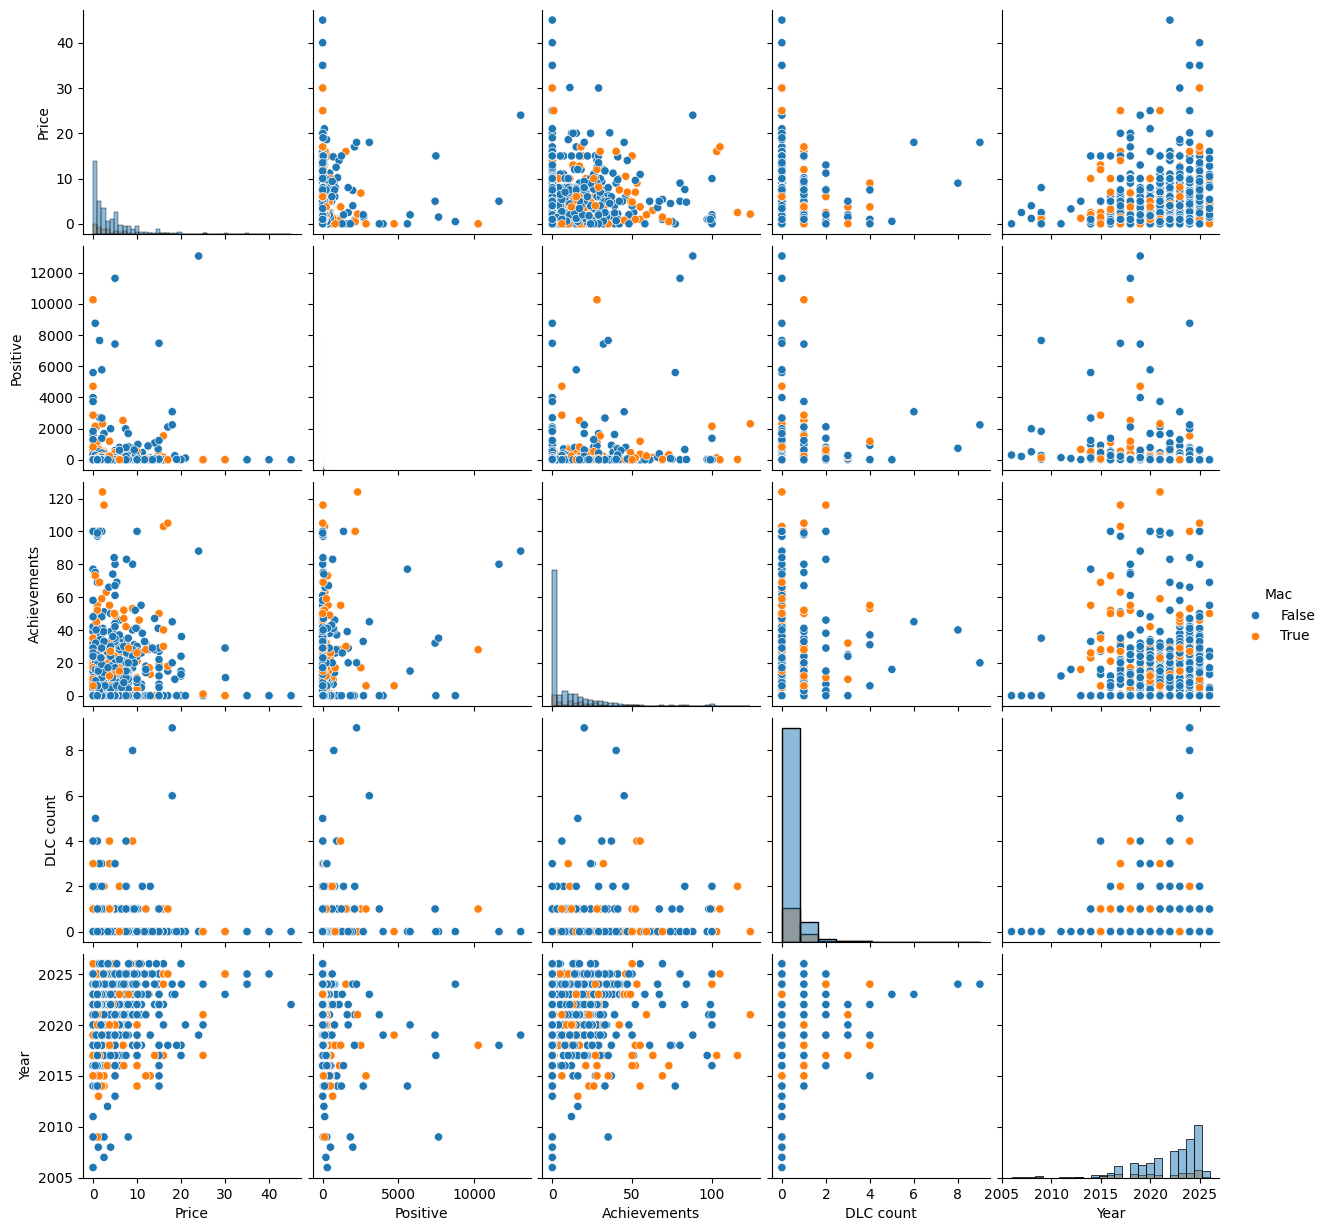

In [ ]:
sns.pairplot(data[['Price', 'Positive', 'Achievements', 'DLC count', 'Year', 'Mac']].sample(1000),
             hue='Mac', diag_kind='hist')
pass

На диагонали видно, что распределения Price, Achievements и DLC count сильно скошены: у большинства игр значения близки к нулю, большие значения встречаются редко; у большинства игр нет DLC. Гистограмма Positive практически не видна из-за очень сильной скошенности распределения (столбики получаются слишком узкими). Большинство игр вышло в последние годы (примерно 2015–2025). Явных линейных зависимостей между парами признаков не наблюдается. Игры с поддержкой macOS чаще встречаются среди игр с большим числом положительных отзывов.


Гистограмма цены

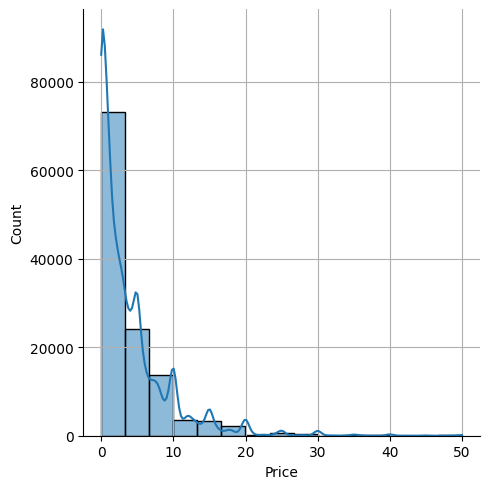

In [ ]:
sns.displot(data['Price'], bins=15, kde=True)
plt.grid()
pass

Распределение цены сильно скошено вправо: больше всего бесплатных и дешёвых игр (до $10),
с ростом цены количество игр быстро убывает.

Совместный график

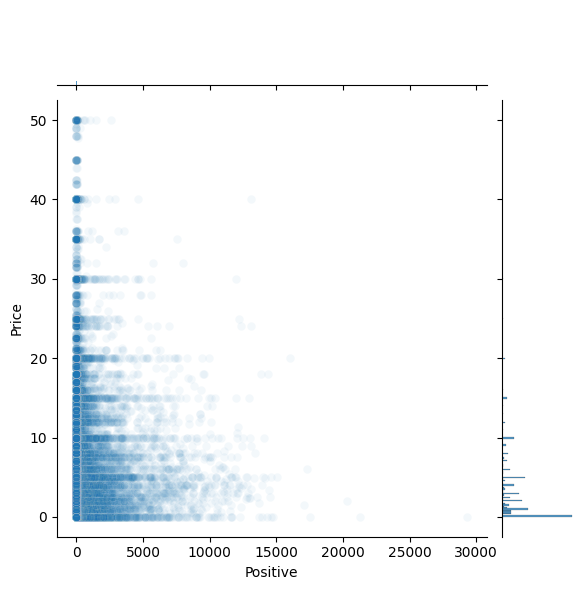

In [ ]:
sns.jointplot(x='Positive', y='Price', alpha=.05, data=data)
pass

Ящики с усами: распределение цены отдельно для игр с поддержкой Mac и без неё

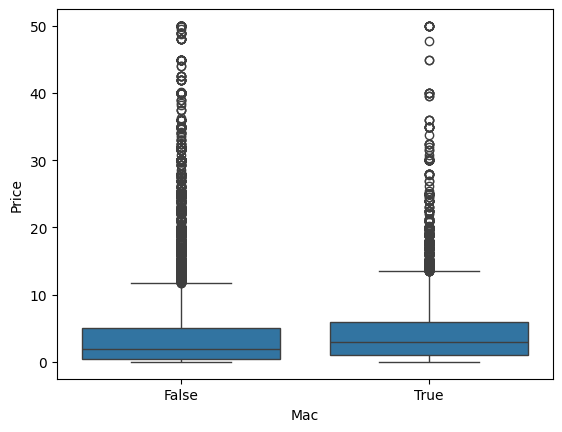

In [ ]:
sns.boxplot(x='Mac', y='Price', data=data)
pass

Скрипичный график: то же самое, но видна форма распределения

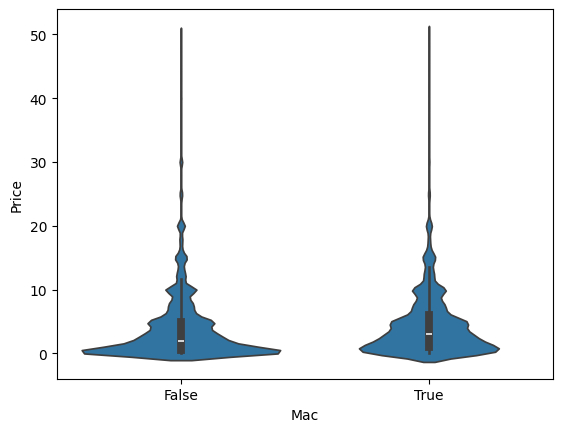

In [ ]:
sns.violinplot(x='Mac', y='Price', data=data)
pass

Медианная цена игр с поддержкой macOS немного выше, чем у игр без неё (примерно $3 против $2); выше и весь ящик (середина распределения). На скрипичном графике видно, что среди игр без поддержки Mac больше бесплатных и очень дешёвых игр. Форма распределения в обеих группах похожая: основная масса игр дешёвая, есть длинный хвост дорогих игр. Различие небольшое, поэтому признак Mac сам по себе слабо определяет цену.

Ящики с усами цены для каждого года выхода.

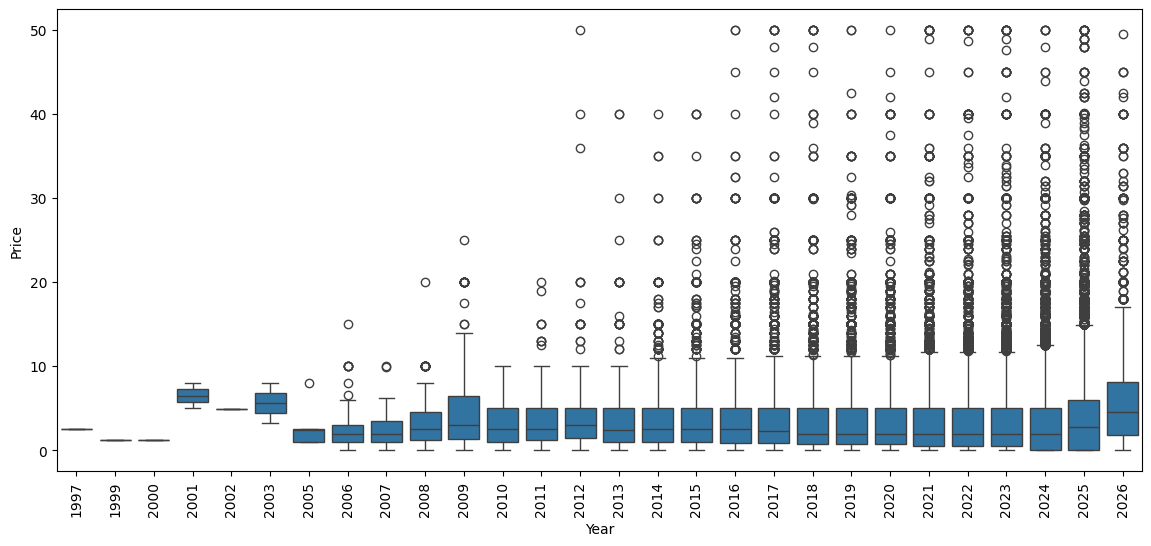

In [ ]:
plt.figure(figsize=(14, 6))
sns.boxplot(x='Year', y='Price', data=data)
plt.xticks(rotation=90)
pass

С 2008 по 2024 год медианная цена почти не меняется (около 2–3 доллоров), распределение цен в эти годы похожее. В 2025 и особенно 2026 году цены заметно выше (медиана около 4–5 доллоров) — вероятно, потому что новые игры ещё не успели подешеветь. До 2008 года игр в датасете очень мало, поэтому ящики для этих лет ненадёжны и выводы по ним делать не стоит. Число точек над усами растёт с годами, потому что с каждым годом в Steam выходит всё больше игр. В целом год выхода слабо связан с ценой; проверим это по коэффициенту корреляции.

Матрица коэффициентов корреляции для всех числовых признаков.
Значения от -1 до 1: около 1 — признаки растут вместе, около -1 — один растёт, другой убывает,
около 0 — линейной связи нет.

In [ ]:
corr_mat = data.corr(numeric_only=True)
corr_mat

,Price,Peak CCU,Required age,DLC count,Windows,Mac,Linux,Metacritic score,Positive,Negative,Achievements,Recommendations,Average playtime forever,Median playtime forever,Year,Owners
Price,1.000000,0.114123,0.035314,0.090814,-0.014536,0.034761,0.012134,0.059003,0.067177,0.064991,0.112977,0.125778,0.167412,0.176033,0.027506,0.020717
Peak CCU,0.114123,1.000000,0.068791,0.163980,0.002657,0.047509,0.020553,0.161750,0.518995,0.429807,0.144069,0.533506,0.435690,0.291360,-0.044999,0.386728
Required age,0.035314,0.068791,1.000000,0.045216,-0.009703,-0.001453,-0.000776,0.130847,0.136391,0.179751,0.025994,0.153573,0.085443,0.059060,-0.098114,0.150348
DLC count,0.090814,0.163980,0.045216,1.000000,0.004871,0.075171,0.064546,0.150238,0.210332,0.228688,0.231800,0.220879,0.218798,0.184997,-0.067129,0.175211
Windows,-0.014536,0.002657,-0.009703,0.004871,1.000000,-0.028397,-0.011117,0.003124,0.003609,0.003701,0.009590,0.003664,0.003603,0.002963,0.006992,0.003313
Mac,0.034761,0.047509,-0.001453,0.075171,-0.028397,1.000000,0.544680,0.097259,0.095068,0.074401,0.116046,0.079413,0.095026,0.088969,-0.159287,0.094939
Linux,0.012134,0.020553,-0.000776,0.064546,-0.011117,0.544680,1.000000,0.067944,0.066627,0.047323,0.117065,0.050778,0.059307,0.053800,-0.099232,0.069296
Metacritic score,0.059003,0.161750,0.130847,0.150238,0.003124,0.097259,0.067944,1.000000,0.360110,0.339488,0.121896,0.359603,0.243379,0.179771,-0.264362,0.357796
Positive,0.067177,0.518995,0.136391,0.210332,0.003609,0.095068,0.066627,0.360110,1.000000,0.736657,0.166378,0.874625,0.401932,0.250364,-0.199369,0.717407
Negative,0.064991,0.429807,0.179751,0.228688,0.003701,0.074401,0.047323,0.339488,0.736657,1.000000,0.172880,0.685393,0.423916,0.275371,-0.251182,0.696872


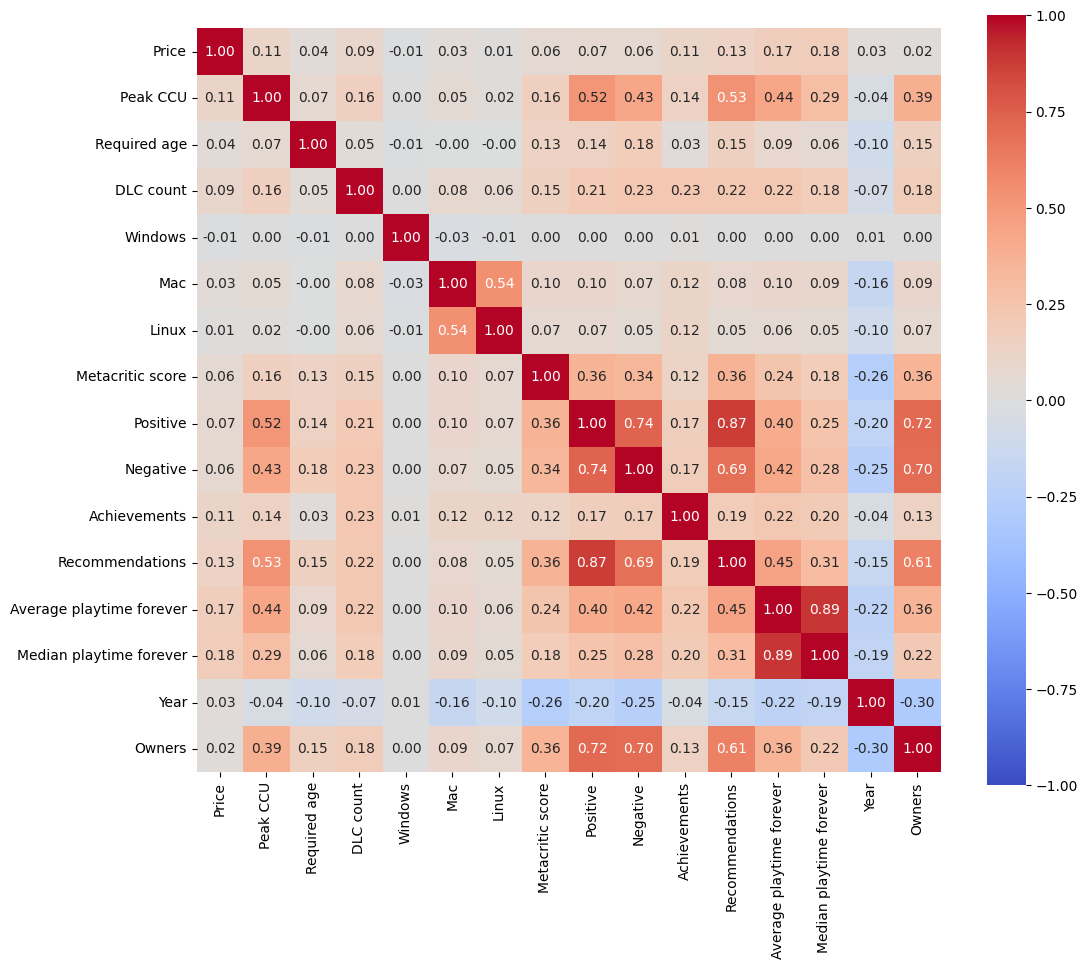

In [ ]:
plt.figure(figsize=(12, 10))
sns.heatmap(corr_mat, square=True, annot=True, fmt='.2f', vmin=-1, vmax=1, cmap='coolwarm')
pass

Пары признаков с корреляцией больше 0.5 по модулю (каждая пара один раз)

In [ ]:
corr_mat.where(np.triu(np.abs(corr_mat) > 0.5, k=1)).stack().sort_values(ascending=False)

Average playtime forever  Median playtime forever    0.893315
Positive                  Recommendations            0.874625
                          Negative                   0.736657
                          Owners                     0.717407
Negative                  Owners                     0.696872
                          Recommendations            0.685393
Recommendations           Owners                     0.610305
Mac                       Linux                      0.544680
Peak CCU                  Recommendations            0.533506
                          Positive                   0.518995
dtype: float64

Корреляция цены с каждым признаком, от самой сильной к самой слабой

In [ ]:
corr_mat.loc['Price'].sort_values(ascending=False)

,Price
Price,1.000000
Median playtime forever,0.176033
Average playtime forever,0.167412
Recommendations,0.125778
Peak CCU,0.114123
Achievements,0.112977
DLC count,0.090814
Positive,0.067177
Negative,0.064991
Metacritic score,0.059003


Сильнее всего коррелируют Average и Median playtime forever (0.99) — почти дублируют друг друга. Также связаны Positive с Negative (0.61), Recommendations (0.60) и Owners (0.57) — все они отражают популярность игры; и Mac с Linux (0.55) — игры часто портируют сразу на обе платформы.

Корреляция цены со всеми признаками очень слабая: максимум — с Recommendations (0.11) и Positive (0.09), с Year — всего 0.03. Ни один признак сам по себе не определяет цену, поэтому качество модели, скорее всего, будет ниже, чем в задаче о квартирах.

## 4. Пропущенные значения

Сколько пропущенных значений (NaN) в каждом столбце

In [ ]:
data.isna().sum()

,0
Price,0
Peak CCU,0
Required age,0
DLC count,0
Windows,0
Mac,0
Linux,0
Metacritic score,0
Positive,0
Negative,0


В числовых признаках пропусков нет. Пропуски есть только в признаке Genres.
Заполнять их самым частым значением, как на лекции, неправильно: тогда игрួ без жанров
получили бы чужие жанры. Поэтому заполним пропуски значением 'Unknown' — это будет
отдельная категория «жанр не указан» (по сути, индикатор пропущенного значения).

In [ ]:
data['Genres'] = data['Genres'].fillna('Unknown')
data.isna().sum()

,0
Price,0
Peak CCU,0
Required age,0
DLC count,0
Windows,0
Mac,0
Linux,0
Metacritic score,0
Positive,0
Negative,0


#5. Бинаризация номинальных признаков

Бинарные признаки Windows, Mac, Linux заменим на числовые: False -> 0, True -> 1.

In [ ]:
data['Windows'] = pd.factorize(data['Windows'])[0]
data['Mac'] = pd.factorize(data['Mac'])[0]
data['Linux'] = pd.factorize(data['Linux'])[0]

Признак Genres содержит несколько жанров через запятую (например, "Action,Indie,RPG").
Применим бинаризацию (one-hot encoding): для каждого жанра создадим отдельный признак,
равный 1, если у игры есть этот жанр, и 0 иначе. В отличие от лекции, у одной игры может
быть несколько единиц, так как жанров у игры может быть несколько.

Некоторые жанры встречаются очень редко (например, 360 Video, Documentary, Episodic — всего
у одной игры). По таким признакам модель ничему научиться не может, а после стандартизации
игры с редким жанром оказываются очень далеко от остальных, что мешает методу ближайших
соседей. Поэтому оставляем только жанры, которые встречаются хотя бы у 100 игр.

In [ ]:
# Разрезаем строку жанров по запятой и создаём столбец-флажок для каждого жанра
Genres_dummies = data['Genres'].str.get_dummies(sep=',').add_prefix('Genre_')
Genres_dummies.sum().sort_values(ascending=False)
Genres_dummies = Genres_dummies.loc[:, Genres_dummies.sum() >= 100]
Genres_dummies.shape
Genres_dummies.head()

,Genre_Action,Genre_Adventure,Genre_Animation & Modeling,Genre_Audio Production,Genre_Casual,Genre_Design & Illustration,Genre_Early Access,Genre_Education,Genre_Free To Play,Genre_Game Development,Genre_Gore,Genre_Indie,Genre_Massively Multiplayer,Genre_Photo Editing,Genre_RPG,Genre_Racing,Genre_Simulation,Genre_Software Training,Genre_Sports,Genre_Strategy,Genre_Unknown,Genre_Utilities,Genre_Video Production,Genre_Violent
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0
4,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [ ]:
data = pd.concat((data, Genres_dummies), axis=1)
data = data.drop(['Genres'], axis=1)
data.head()

,Price,Peak CCU,Required age,DLC count,Windows,Mac,Linux,Metacritic score,Positive,Negative,Achievements,Recommendations,Average playtime forever,Median playtime forever,Year,Owners,Genre_Action,Genre_Adventure,Genre_Animation & Modeling,Genre_Audio Production,Genre_Casual,Genre_Design & Illustration,Genre_Early Access,Genre_Education,Genre_Free To Play,Genre_Game Development,Genre_Gore,Genre_Indie,Genre_Massively Multiplayer,Genre_Photo Editing,Genre_RPG,Genre_Racing,Genre_Simulation,Genre_Software Training,Genre_Sports,Genre_Strategy,Genre_Unknown,Genre_Utilities,Genre_Video Production,Genre_Violent
0,0.00,0,0,0,0,0,0,0,0,0,0,0,0,0,2023,0.0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
1,5.24,0,0,0,0,0,0,0,252,3,0,231,8,8,2016,10000.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,4.99,0,0,0,0,1,0,0,21,3,0,0,0,0,2019,10000.0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,8.99,1,0,1,0,0,0,0,0,0,19,0,0,0,2024,10000.0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0
4,4.99,0,0,0,0,0,0,0,0,0,0,0,0,0,2025,10000.0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


#6. Нормализация количественных признаков

Нормализация нужна, потому что признаки у нас измеряются в очень разных масштабах: Positive — тысячи,
Year — около 2000, флажки жанров и платформ — 0 или 1. Без нормализации расстояние почти
полностью определялось бы признаками с большими значениями, а остальные бы не учитывались.

In [ ]:
data_stand = (data - data.mean(axis=0)) / data.std(axis=0)

In [ ]:
data_stand.describe()

,Price,Peak CCU,Required age,DLC count,Windows,Mac,Linux,Metacritic score,Positive,Negative,Achievements,Recommendations,Average playtime forever,Median playtime forever,Year,Owners,Genre_Action,Genre_Adventure,Genre_Animation & Modeling,Genre_Audio Production,Genre_Casual,Genre_Design & Illustration,Genre_Early Access,Genre_Education,Genre_Free To Play,Genre_Game Development,Genre_Gore,Genre_Indie,Genre_Massively Multiplayer,Genre_Photo Editing,Genre_RPG,Genre_Racing,Genre_Simulation,Genre_Software Training,Genre_Sports,Genre_Strategy,Genre_Unknown,Genre_Utilities,Genre_Video Production,Genre_Violent
count,1.216710e+05,1.216710e+05,1.216710e+05,1.216710e+05,1.216710e+05,1.216710e+05,1.216710e+05,1.216710e+05,1.216710e+05,1.216710e+05,1.216710e+05,1.216710e+05,1.216710e+05,1.216710e+05,1.216710e+05,1.216710e+05,1.216710e+05,1.216710e+05,1.216710e+05,1.216710e+05,1.216710e+05,1.216710e+05,1.216710e+05,1.216710e+05,1.216710e+05,1.216710e+05,1.216710e+05,1.216710e+05,1.216710e+05,1.216710e+05,1.216710e+05,1.216710e+05,1.216710e+05,1.216710e+05,1.216710e+05,1.216710e+05,1.216710e+05,1.216710e+05,1.216710e+05,1.216710e+05
mean,1.756633e-16,-3.036732e-17,4.006150e-17,9.343791e-18,-4.087908e-19,4.438301e-17,-2.394346e-17,-1.027817e-17,5.606275e-18,2.803137e-17,-2.569542e-18,-2.662980e-17,-2.055634e-17,2.803137e-18,-2.524319e-14,1.868758e-18,8.818203e-17,7.679428e-17,1.658523e-17,-1.617644e-17,7.872144e-17,-6.307059e-18,5.325961e-17,-4.905490e-17,-2.522824e-17,-1.366529e-17,-1.448288e-17,1.006793e-16,6.750889e-17,-4.321503e-18,1.273092e-17,-1.226373e-17,4.344863e-17,-1.787000e-17,-2.639621e-17,-1.985556e-17,-5.793150e-17,-1.985556e-17,-1.109575e-17,2.511144e-17
std,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
min,-7.741747e-01,-1.437512e-01,-8.254483e-02,-2.855184e-01,-1.901996e-02,-4.501131e-01,-3.778369e-01,-1.642264e-01,-2.026673e-01,-2.335445e-01,-6.252341e-01,-1.997881e-01,-2.820245e-01,-2.805985e-01,-7.607441e+00,-3.119394e-01,-7.715186e-01,-7.629887e-01,-5.864327e-02,-3.985915e-02,-8.404120e-01,-6.532428e-02,-3.199081e-01,-5.927494e-02,-3.330869e-01,-4.870971e-02,-4.573781e-02,-1.405052e+00,-1.399412e-01,-3.673834e-02,-4.485409e-01,-1.821676e-01,-4.904476e-01,-3.985915e-02,-1.982447e-01,-4.682091e-01,-2.725108e-01,-9.084881e-02,-4.853988e-02,-5.821841e-02
25%,-6.688497e-01,-1.437512e-01,-8.254483e-02,-2.855184e-01,-1.901996e-02,-4.501131e-01,-3.778369e-01,-1.642264e-01,-2.026673e-01,-2.335445e-01,-6.252341e-01,-1.997881e-01,-2.820245e-01,-2.805985e-01,-5.284751e-01,-2.083435e-01,-7.715186e-01,-7.629887e-01,-5.864327e-02,-3.985915e-02,-8.404120e-01,-6.532428e-02,-3.199081e-01,-5.927494e-02,-3.330869e-01,-4.870971e-02,-4.573781e-02,-1.405052e+00,-1.399412e-01,-3.673834e-02,-4.485409e-01,-1.821676e-01,-4.904476e-01,-3.985915e-02,-1.982447e-01,-4.682091e-01,-2.725108e-01,-9.084881e-02,-4.853988e-02,-5.821841e-02
50%,-3.547898e-01,-1.437512e-01,-8.254483e-02,-2.855184e-01,-1.901996e-02,-4.501131e-01,-3.778369e-01,-1.642264e-01,-1.973999e-01,-2.257843e-01,-5.730211e-01,-1.997881e-01,-2.820245e-01,-2.805985e-01,3.948683e-01,-2.083435e-01,-7.715186e-01,-7.629887e-01,-5.864327e-02,-3.985915e-02,-8.404120e-01,-6.532428e-02,-3.199081e-01,-5.927494e-02,-3.330869e-01,-4.870971e-02,-4.573781e-02,7.117117e-01,-1.399412e-01,-3.673834e-02,-4.485409e-01,-1.821676e-01,-4.904476e-01,-3.985915e-02,-1.982447e-01,-4.682091e-01,-2.725108e-01,-9.084881e-02,-4.853988e-02,-5.821841e-02
75%,1.814101e-01,-1.437512e-01,-8.254483e-02,-2.855184e-01,-1.901996e-02,-4.501131e-01,-3.778369e-01,-1.

## 7. Разбиение на обучающую и тестовую выборки


In [ ]:
from sklearn.model_selection import train_test_split

X = data_stand.drop(['Price', 'Windows'], axis=1) #Windows почти константный признак, убираем
y = data['Price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

print(X_train.shape, X_test.shape)

(91253, 38) (30418, 38)


#8. Запускаем регрессию ближайших соседей.

анализ данных показал, что линейной связи цены с признаками почти нет, поэтому линейная модель, скорее всего, работала бы плохо,а kNN может уловить и нелинейные зависимости; данные уже стандартизированы, что необходимо для kNN, так как он работает с расстояниями.

In [ ]:
from sklearn.neighbors import KNeighborsRegressor

model = KNeighborsRegressor(n_neighbors=7)
model.fit(X_train, y_train)

KNeighborsRegressor(n_neighbors=7)

In [ ]:
y_train_predict = model.predict(X_train)
y_test_predict  = model.predict(X_test)

#9. Ошибки на обучающих и тестовых выборках

In [ ]:
from sklearn.metrics import mean_squared_error, r2_score

RMSE_table = pd.DataFrame(columns=('train', 'test'))
R2_table   = pd.DataFrame(columns=('train', 'test'))

In [ ]:
RMSE_train = mean_squared_error(y_train, y_train_predict)**.5
RMSE_test  = mean_squared_error(y_test,  y_test_predict)**.5
R2_train = r2_score(y_train, y_train_predict)
R2_test  = r2_score(y_test,  y_test_predict)

In [ ]:
RMSE_table.loc['kNN, k=7', :] = (RMSE_train, RMSE_test)
RMSE_table

,train,test
"kNN, k=7",4.085438,4.709973


In [ ]:
R2_table.loc['kNN, k=7', :] = (R2_train, R2_test)
R2_table

,train,test
"kNN, k=7",0.387354,0.188654


При k = 7 ошибка на тестовой выборке RMSE ≈ 4.71, R^2 ≈ 0.19: модель объясняет около 19%
разброса цен. Это лучше, чем постоянное предсказание средней цены (для него R² = 0,
а RMSE ≈ 5.2), но качество невысокое. Это согласуется с анализом данных: корреляция цены
со всеми признаками слабая, ни один признак сам по себе не определяет цену.

На обучающей выборке ошибка заметно меньше (R^2 ≈ 0.39). Отчасти это переобучение,
отчасти особенность метода: для обучающего объекта он сам является одним из своих
ближайших соседей, поэтому ошибка на обучающей выборке занижена. Реальное качество
модели показывает ошибка на тестовой выборке.

`Подбор гиперпараметра k`


In [ ]:
from sklearn.model_selection import GridSearchCV

k_arr = np.array([1, 2, 3, 4, 5, 7, 10, 15, 20, 30, 40, 50])

params = {
    'n_neighbors': k_arr,
}

from sklearn.model_selection import GridSearchCV

k_arr = np.array([1, 2, 3, 4, 5, 7, 10, 15, 20, 30, 40, 50])

params = {
    'n_neighbors': k_arr,
}

model = GridSearchCV(KNeighborsRegressor(), params, scoring='neg_mean_squared_error', n_jobs=-1)
model.fit(X_train, y_train)

model.best_score_, model.best_params_

(np.float64(-20.85310334259024), {'n_neighbors': np.int64(40)})

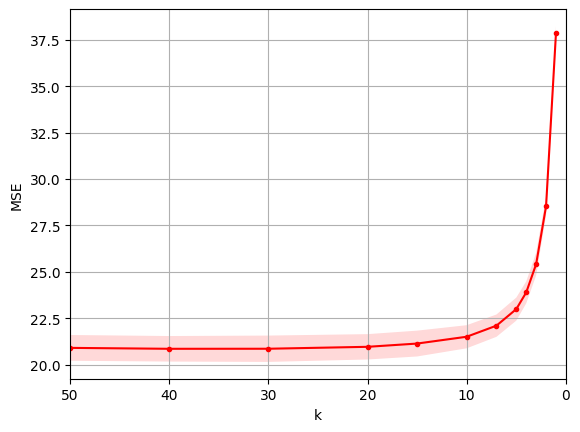

In [ ]:
MSE_arr = -model.cv_results_['mean_test_score']
std_arr = model.cv_results_['std_test_score']
plt.plot(k_arr, MSE_arr, 'r.-')
plt.fill_between(k_arr, MSE_arr - std_arr, MSE_arr + std_arr, alpha=0.15, facecolor='red')
plt.xlim([max(k_arr), 0])
plt.grid()
plt.xlabel('k')
plt.ylabel('MSE')
pass

График показывает зависимость ошибки (MSE на кросс-валидации) от числа соседей k.
При маленьком k ошибка большая (MSE ≈ 37.7 при k = 1): модель опирается на одну-две
самые похожие игры и подстраивается под случайные особенности отдельных игр (переобучение).
С ростом k ошибка быстро уменьшается, а начиная примерно с k = 20 почти не меняется
(MSE ≈ 21). Оптимальное значение k = 40 (MSE ≈ 20.85, RMSE ≈ 4.57), однако различия
между k = 30, 40 и 50 малы по сравнению с разбросом ошибки между частями кросс-валидации.

Теперь обучим модель при найденном оптимальном значении гиперпараметра:

In [ ]:
best_k = model.best_params_['n_neighbors']

knn = KNeighborsRegressor(n_neighbors=best_k)
knn.fit(X_train, y_train)

y_train_predict = knn.predict(X_train)
y_test_predict  = knn.predict(X_test)

RMSE_table.loc[f'kNN, k={best_k}', :] = (mean_squared_error(y_train, y_train_predict)**.5,
                                         mean_squared_error(y_test,  y_test_predict)**.5)
R2_table.loc[f'kNN, k={best_k}', :]   = (r2_score(y_train, y_train_predict),
                                         r2_score(y_test,  y_test_predict))
RMSE_table

,train,test
"kNN, k=7",4.085438,4.709973
"kNN, k=40",4.440588,4.569794


In [ ]:
   R2_table

,train,test
"kNN, k=7",0.387354,0.188654
"kNN, k=40",0.276209,0.23623


#13. Вывод

## 13. Выводы

- Решалась задача регрессии: предсказание цены игры в Steam методом k ближайших соседей.
- Данные очищены от выбросов, пропуски в жанрах заполнены, категориальные признаки
  бинаризованы, все признаки стандартизированы.
- Оптимальное число соседей k = 40. На тестовой выборке RMSE ≈ 4.57, R² ≈ 0.24.
  Ошибки на обучающей и тестовой выборках близки — переобучения нет.
- Качество невысокое: корреляция цены со всеми признаками слабая, а цена в основном зависит
  от факторов, которых нет в данных (разработчик, бюджет, известность серии).
- Отзывы, владельцы и время в игре известны только после выхода игры, поэтому модель
  подходит для анализа уже вышедших игр, но не для выбора цены новой.